# Prediction of Sodium Concentration from Mean Reflectance Spectra


This notebook predicts sodium concentration (Na⁺) from mean reflectance spectra of hyperspectral images using PLSR, for both VNIR and SWIR sensors. Laboratory Na⁺ measurements serve as ground truth. Models are saved to disk for use in Notebook 4.

The dataset consists of 48 fish-fillet samples (24 fish × 2 treatments: control C and salted K). Na⁺ values are averaged across 3 layers per sample.

**Notebook structure**

1. **Setup** – Libraries and plot style.
2. **Configuration** – Sensor paths.
3. **Helper Functions** – `pls_predict`, `calculate_vip`, `find_local_maxima`.
4. **Data Loading** – Na⁺ measurements (shared across sensors).
5. **VNIR Analysis** – Merge spectra, train PLSR, results.
6. **SWIR Analysis** – Same pipeline on SWIR spectra.
7. **Cross-Sensor Comparison** – Performance table and side-by-side VIP.

## 1. Setup & Requirements

In [1]:
from collections import Counter

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import joblib
from scipy.signal import find_peaks
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut


In [2]:
custom_params = {
    "axes.spines.right": False,
    "axes.spines.top": False,
    "font.family": "arial",
    "figure.figsize": (5, 3),
    "figure.dpi": 150,
    "lines.linewidth": 1.5,
    "axes.linewidth": 1.0,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",
    "savefig.dpi": 300,
}
sns.set_theme(style="ticks", context="paper", font_scale=1.5, rc=custom_params)
plt.rcParams.update(custom_params)
sns.set_palette("tab10")


## 2. Configuration

Paths to the pre-computed MSC-corrected mean-spectra files for each sensor.

In [3]:
SENSORS = {
    "VNIR": "../output/spectra/vnir_mean_spectra_msc.csv",
    "SWIR": "../output/spectra/swir_mean_spectra_msc.csv",
}
MEASUREMENTS_FILE = "../data/measurements/measurements_sodium.csv"


## 3. Helper Functions

In [4]:
def calculate_vip(pls_model, X):
    """VIP (Variable Importance in Projection) scores for a fitted PLSRegression."""
    t = pls_model.x_scores_
    w = pls_model.x_weights_
    q = pls_model.y_loadings_
    _, p = X.shape
    s = np.sum(t**2, axis=0) * (q**2).ravel()
    total_s = np.sum(s)
    vip = np.zeros(p)
    for i in range(p):
        vip[i] = np.sqrt(p * np.sum(s * (w[i, :] ** 2)) / total_s)
    return vip


def pls_predict(X, y, groups, max_components=10, cv=5):
    """PLSR with Leave-One-Group-Out (LOGO) CV.

    Each fish is left out once; inner GroupKFold selects optimal n_components.
    All out-of-fold predictions are pooled for one global RMSE and R².
    The final model is refitted on ALL data using the mode n_components.

    Returns
    -------
    dict : model, vip, metrics, n_components, rmse_cv, predictions,
           n_components_per_fold
    """
    logo = LeaveOneGroupOut()
    groups = np.asarray(groups)
    all_y_true, all_y_pred = [], []
    all_n_components = []
    rmse_cv_matrix = []

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        train_groups = groups[train_idx]

        n_inner = min(cv, len(np.unique(train_groups)))
        gkf = GroupKFold(n_splits=n_inner)
        rmse_list = []
        for n in range(1, max_components + 1):
            fold_rmse = []
            for tr, val in gkf.split(X_train, y_train, train_groups):
                pls = PLSRegression(n_components=n)
                pls.fit(X_train[tr], y_train[tr])
                pred = pls.predict(X_train[val])
                fold_rmse.append(np.sqrt(mean_squared_error(y_train[val], pred)))
            rmse_list.append(np.mean(fold_rmse))

        opt_n = int(np.argmin(rmse_list)) + 1
        all_n_components.append(opt_n)
        rmse_cv_matrix.append(rmse_list)

        model = PLSRegression(n_components=opt_n).fit(X_train, y_train)
        y_pred = model.predict(X_test).ravel()
        all_y_true.extend(y_test.tolist())
        all_y_pred.extend(y_pred.tolist())

    all_y_true = np.array(all_y_true)
    all_y_pred = np.array(all_y_pred)

    global_rmse = np.sqrt(mean_squared_error(all_y_true, all_y_pred))
    global_r2 = r2_score(all_y_true, all_y_pred)
    rmse_cv_mean = np.mean(rmse_cv_matrix, axis=0).tolist()

    best_n = Counter(all_n_components).most_common(1)[0][0]
    final_model = PLSRegression(n_components=best_n).fit(X, y)
    vip = calculate_vip(final_model, X)

    n_folds = len(np.unique(groups))
    print(f"--- PLSR Leave-One-Group-Out CV ({n_folds} folds) ---")
    print(f"n_components per fold: {dict(Counter(all_n_components))} -> mode = {best_n}")
    print(f"Test RMSE (global): {global_rmse:.2f}")
    print(f"Test R2   (global): {global_r2:.4f}")

    return {
        "model": final_model, "vip": vip,
        "metrics": {"rmse": global_rmse, "r2": global_r2},
        "n_components": best_n,
        "rmse_cv": rmse_cv_mean,
        "predictions": {"y_test": all_y_true, "y_pred_test": all_y_pred},
        "n_components_per_fold": all_n_components,
    }


def find_local_maxima(df, th, prominence=0.0):
    """Find local maxima above threshold in a two-column DataFrame."""
    x_vals = df.iloc[:, 0].values
    scores = df.iloc[:, 1].values
    peaks, _ = find_peaks(scores, height=th, prominence=prominence)
    return [float(x_vals[i]) for i in peaks]


## 4. Data Loading & Preparation

### 4.1. Sodium Measurements

Na⁺ concentrations are measured in three layers per fillet and averaged to one value per sample. This reference table is shared across both sensor analyses.

In [5]:
df_na = pd.read_csv(MEASUREMENTS_FILE)
print(f"Loaded measurements: {df_na.shape[0]} rows, {df_na.shape[1]} columns")
df_na.head()

Loaded measurements: 144 rows, 4 columns


,Fish,Treatment,Layer,Na
0,1,C,1,244.664671
1,1,C,2,261.991091
2,1,C,3,300.863539
3,1,K,1,912.242082
4,1,K,2,964.285714


In [6]:
# Average Na+ across the 3 layers for each sample
df_na = df_na.groupby(["Fish", "Treatment"], as_index=False).agg({"Na": "mean"})
print(f"After averaging layers: {df_na.shape[0]} samples")
df_na.head()


After averaging layers: 48 samples


,Fish,Treatment,Na
0,1,C,269.173100
1,1,K,1167.578546
2,2,C,269.064066
3,2,K,998.658637
4,3,C,280.452893


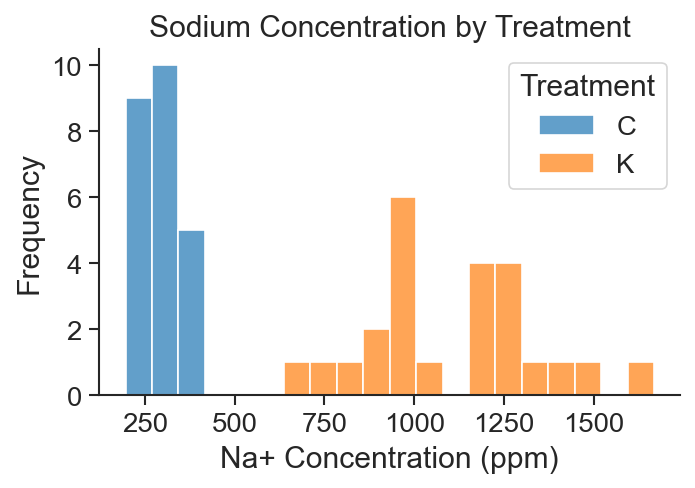

In [7]:
sns.histplot(data=df_na, x="Na", hue="Treatment", bins=20, alpha=0.7)
plt.xlabel("Na+ Concentration (ppm)")
plt.ylabel("Frequency")
plt.title("Sodium Concentration by Treatment")
plt.show()


## 5. VNIR Analysis

### 5.1. Load Spectra & Merge

In [8]:
df_spectra_vnir = pd.read_csv(SENSORS["VNIR"], sep=";")
print(f"VNIR spectra: {df_spectra_vnir.shape[0]} samples, "
      f"{df_spectra_vnir.shape[1] - 2} wavelengths")

merged_vnir = pd.merge(df_na, df_spectra_vnir, on=["Fish", "Treatment"], how="left")
print(f"Merged VNIR: {merged_vnir.shape[0]} samples | missing: {merged_vnir.isnull().sum().sum()}")
merged_vnir.head()


VNIR spectra: 48 samples, 224 wavelengths
Merged VNIR: 48 samples | missing: 0


,Fish,Treatment,Na,397.66,400.28,402.90,405.52,408.13,410.75,413.37,...,978.46,981.27,984.09,986.90,989.72,992.54,995.35,998.17,1000.99,1003.81
0,1,C,269.173100,0.200511,0.195683,0.185905,0.176405,0.167391,0.160209,0.154668,...,0.261150,0.261030,0.261486,0.262144,0.263002,0.264331,0.266214,0.268216,0.269868,0.270191
1,1,K,1167.578546,0.195506,0.189565,0.180101,0.171504,0.162251,0.155959,0.151745,...,0.267665,0.267710,0.267850,0.268693,0.269600,0.271067,0.272684,0.274569,0.276414,0.276697
2,2,C,269.064066,0.201953,0.197390,0.185669,0.175671,0.167535,0.160067,0.154439,...,0.275621,0.275432,0.275525,0.276149,0.277242,0.278155,0.279898,0.281902,0.283909,0.284255
3,2,K,998.658637,0.199467,0.194921,0.185079,0.175170,0.168358,0.162437,0.157446,...,0.271280,0.271335,0.271801,0.272360,0.273434,0.274643,0.276564,0.278676,0.280382,0.280647
4,3,C,280.452893,0.206080,0.198821,0.187977,0.178707,0.172142,0.164852,0.158099,...,0.261865,0.261993,0.262431,0.263477,0.264719,0.266142,0.268057,0.270317,0.272340,0.272785


In [9]:
X_vnir = merged_vnir.iloc[:, 3:].values
y_vnir = merged_vnir["Na"].values
groups_vnir = merged_vnir["Fish"].values
print(f"VNIR features: {X_vnir.shape}  |  Target: {y_vnir.shape}")


VNIR features: (48, 224)  |  Target: (48,)


### 5.2. Model Training & Evaluation

In [10]:
result_vnir = pls_predict(X_vnir, y_vnir, groups=groups_vnir,
                         max_components=30, cv=10)


--- PLSR Leave-One-Group-Out CV (24 folds) ---
n_components per fold: {14: 1, 20: 4, 17: 9, 18: 1, 19: 5, 21: 2, 16: 1, 9: 1} -> mode = 17
Test RMSE (global): 228.40
Test R2   (global): 0.7325


In [11]:
joblib.dump(result_vnir["model"], "../output/models/vnir_plsr_model.pkl")
print("VNIR model saved.")


VNIR model saved.


### 5.3. Results

#### Predicted vs Measured

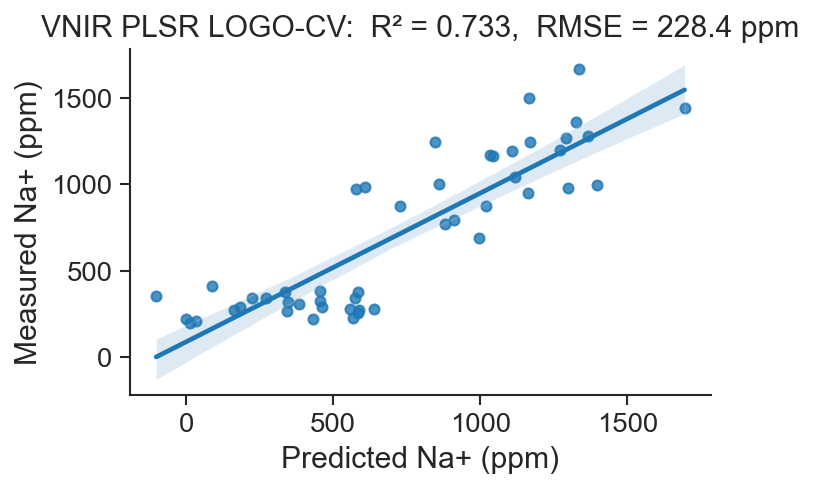

In [12]:
predictions_vnir = pd.DataFrame(result_vnir["predictions"])
rmse_v = result_vnir["metrics"]["rmse"]
r2_v   = result_vnir["metrics"]["r2"]
sns.regplot(data=predictions_vnir, x="y_pred_test", y="y_test")
plt.xlabel("Predicted Na+ (ppm)")
plt.ylabel("Measured Na+ (ppm)")
plt.title(f"VNIR PLSR LOGO-CV:  R² = {r2_v:.3f},  RMSE = {rmse_v:.1f} ppm")
plt.show()


#### RMSE vs Number of Components

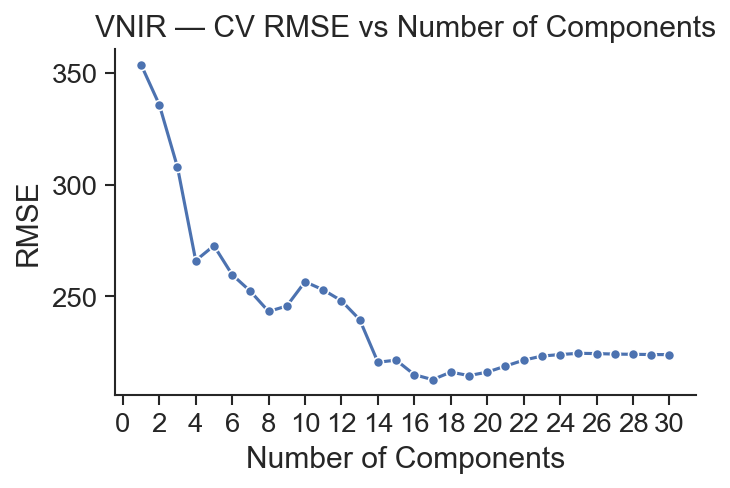

In [13]:
max_comp_v = len(result_vnir["rmse_cv"])
sns.lineplot(x=range(1, max_comp_v + 1), y=result_vnir["rmse_cv"],
             marker="o", linestyle="-", color="b")
plt.xlabel("Number of Components")
plt.xticks(np.arange(0, max_comp_v + 1, step=2))
plt.ylabel("RMSE")
plt.title("VNIR — CV RMSE vs Number of Components")
plt.show()


#### VIP Scores

VNIR wavelengths above VIP threshold: 14


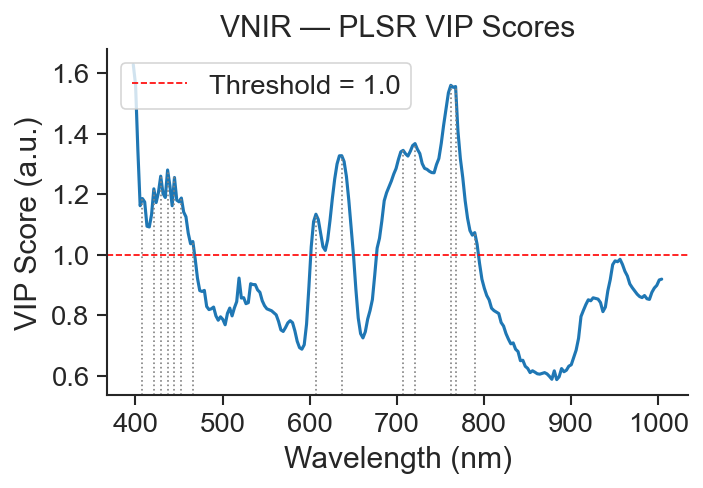

In [14]:
wavelengths_vnir = merged_vnir.columns[3:].astype(float).tolist()
df_vip_vnir = pd.DataFrame({"Wavelength": wavelengths_vnir,
                             "VIP Score": result_vnir["vip"]})
biomarkers_vnir = find_local_maxima(df_vip_vnir, th=1.0)
print(f"VNIR wavelengths above VIP threshold: {len(biomarkers_vnir)}")

sns.lineplot(data=df_vip_vnir, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None)
plt.axhline(y=1.0, color="red", linestyle="--", label="Threshold = 1.0", lw=0.8)
y_min, y_max = plt.ylim()
for x in biomarkers_vnir:
    score = df_vip_vnir.loc[df_vip_vnir["Wavelength"] == x, "VIP Score"].iloc[0]
    ymax_rel = (score - y_min) / (y_max - y_min)
    plt.axvline(x=x, ymax=ymax_rel, color="gray", linestyle=":", lw=0.8)
plt.xlabel("Wavelength (nm)")
plt.ylabel("VIP Score (a.u.)")
plt.legend()
plt.title("VNIR — PLSR VIP Scores")
plt.show()


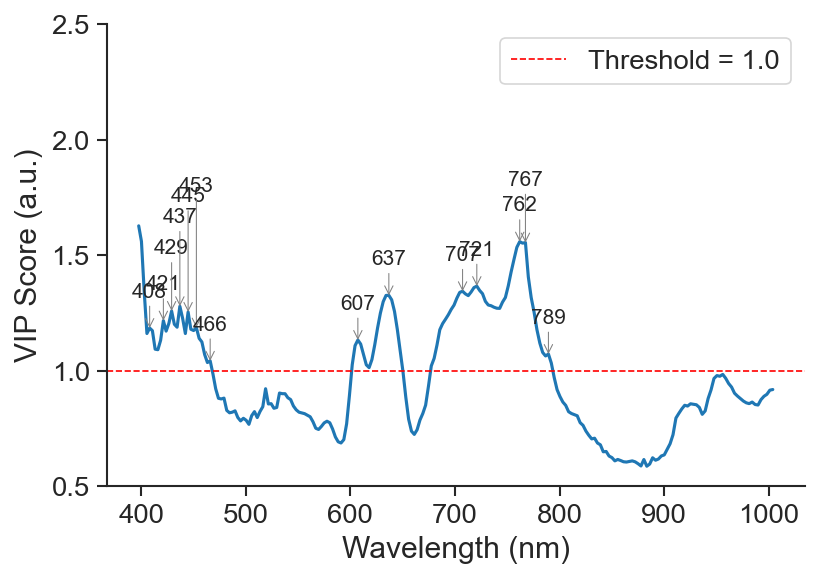

In [26]:
# Annotated VIP
plt.figure(figsize=(6, 4))
sns.lineplot(data=df_vip_vnir, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None)
plt.axhline(y=1.0, color="red", linestyle="--", label="Threshold = 1.0", lw=0.8)
y_min, y_max = plt.ylim()
plt.yticks(np.arange(0.5, 3.0, step=0.5))
prev_x, offset = None, 0
for x in sorted(biomarkers_vnir):
    score = df_vip_vnir.loc[df_vip_vnir["Wavelength"] == x, "VIP Score"].iloc[0]
    offset = (offset + 1) if (prev_x is not None and abs(x - prev_x) < 10) else 0
    prev_x = x
    plt.annotate(f"{int(round(x))}", xy=(x, score),
        xytext=(x, score + (y_max - y_min) * 0.1 * (offset + 1)),
        ha="center", va="bottom", fontsize=10,
        arrowprops=dict(arrowstyle="->", color="gray", lw=0.5, shrinkA=0, shrinkB=0))
plt.xlabel("Wavelength (nm)")
plt.ylabel("VIP Score (a.u.)")
plt.legend()
# plt.title("VNIR — PLSR VIP Scores (annotated)")
plt.show()


## 6. SWIR Analysis

### 6.1. Load Spectra & Merge

In [16]:
df_spectra_swir = pd.read_csv(SENSORS["SWIR"], sep=";")
print(f"SWIR spectra: {df_spectra_swir.shape[0]} samples, "
      f"{df_spectra_swir.shape[1] - 2} wavelengths")

merged_swir = pd.merge(df_na, df_spectra_swir, on=["Fish", "Treatment"], how="left")
print(f"Merged SWIR: {merged_swir.shape[0]} samples | missing: {merged_swir.isnull().sum().sum()}")
merged_swir.head()


SWIR spectra: 48 samples, 270 wavelengths
Merged SWIR: 48 samples | missing: 0


,Fish,Treatment,Na,998.84,1004.48,1010.13,1015.77,1021.41,1027.06,1032.70,...,2449.96,2455.52,2461.09,2466.66,2472.22,2477.79,2483.36,2488.93,2494.50,2500.07
0,1,C,269.173100,0.214580,0.219941,0.225789,0.231892,0.237882,0.244658,0.251252,...,0.027435,0.026573,0.026135,0.027164,0.025565,0.024856,0.024837,0.027818,0.026086,0.025860
1,1,K,1167.578546,0.214556,0.219602,0.224437,0.230615,0.237130,0.244226,0.250860,...,0.029064,0.028763,0.028219,0.027802,0.027461,0.027104,0.026526,0.028508,0.028248,0.027900
2,2,C,269.064066,0.214214,0.219433,0.225147,0.231719,0.238962,0.246674,0.254025,...,0.029732,0.029124,0.028298,0.028232,0.027747,0.027363,0.026758,0.029072,0.028874,0.028497
3,2,K,998.658637,0.217064,0.222025,0.226747,0.232331,0.238537,0.244930,0.250923,...,0.027996,0.027924,0.027053,0.026954,0.026248,0.026285,0.025694,0.027696,0.027347,0.027403
4,3,C,280.452893,0.215228,0.221405,0.227317,0.234075,0.241596,0.249149,0.256534,...,0.032689,0.032709,0.032076,0.031916,0.031647,0.031265,0.031188,0.032555,0.032476,0.032525


In [17]:
X_swir = merged_swir.iloc[:, 3:].values
y_swir = merged_swir["Na"].values
groups_swir = merged_swir["Fish"].values
print(f"SWIR features: {X_swir.shape}  |  Target: {y_swir.shape}")


SWIR features: (48, 270)  |  Target: (48,)


### 6.2. Model Training & Evaluation

In [18]:
result_swir = pls_predict(X_swir, y_swir, groups=groups_swir,
                         max_components=30, cv=10)


--- PLSR Leave-One-Group-Out CV (24 folds) ---
n_components per fold: {8: 9, 9: 15} -> mode = 9
Test RMSE (global): 206.95
Test R2   (global): 0.7804


In [19]:
joblib.dump(result_swir["model"], "../output/models/swir_plsr_model.pkl")
print("SWIR model saved.")


SWIR model saved.


### 6.3. Results

#### Predicted vs Measured

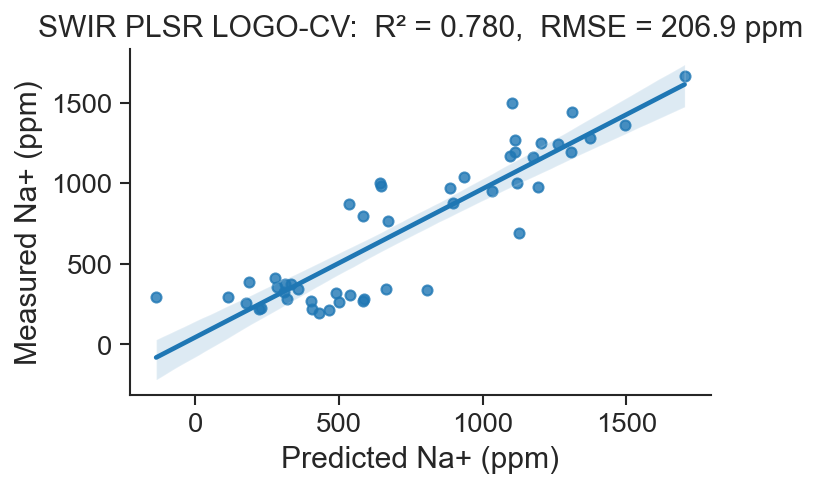

In [20]:
predictions_swir = pd.DataFrame(result_swir["predictions"])
rmse_s = result_swir["metrics"]["rmse"]
r2_s   = result_swir["metrics"]["r2"]
sns.regplot(data=predictions_swir, x="y_pred_test", y="y_test")
plt.xlabel("Predicted Na+ (ppm)")
plt.ylabel("Measured Na+ (ppm)")
plt.title(f"SWIR PLSR LOGO-CV:  R² = {r2_s:.3f},  RMSE = {rmse_s:.1f} ppm")
plt.show()


#### RMSE vs Number of Components

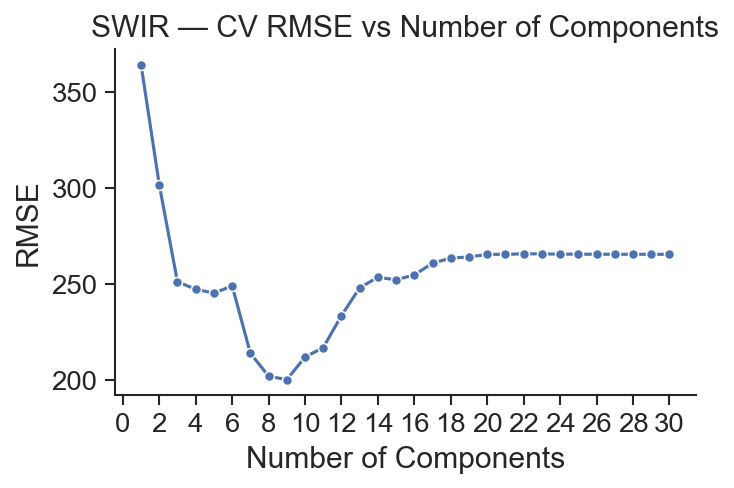

In [21]:
max_comp_s = len(result_swir["rmse_cv"])
sns.lineplot(x=range(1, max_comp_s + 1), y=result_swir["rmse_cv"],
             marker="o", linestyle="-", color="b")
plt.xlabel("Number of Components")
plt.xticks(np.arange(0, max_comp_s + 1, step=2))
plt.ylabel("RMSE")
plt.title("SWIR — CV RMSE vs Number of Components")
plt.show()


#### VIP Scores

SWIR wavelengths above VIP threshold: 17


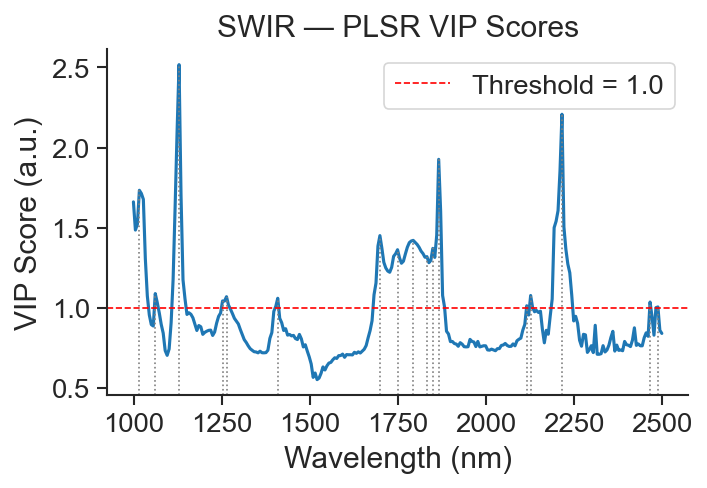

In [22]:
wavelengths_swir = merged_swir.columns[3:].astype(float).tolist()
df_vip_swir = pd.DataFrame({"Wavelength": wavelengths_swir,
                             "VIP Score": result_swir["vip"]})
biomarkers_swir = find_local_maxima(df_vip_swir, th=1.0)
print(f"SWIR wavelengths above VIP threshold: {len(biomarkers_swir)}")

sns.lineplot(data=df_vip_swir, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None)
plt.axhline(y=1.0, color="red", linestyle="--", label="Threshold = 1.0", lw=0.8)
y_min, y_max = plt.ylim()
for x in biomarkers_swir:
    score = df_vip_swir.loc[df_vip_swir["Wavelength"] == x, "VIP Score"].iloc[0]
    ymax_rel = (score - y_min) / (y_max - y_min)
    plt.axvline(x=x, ymax=ymax_rel, color="gray", linestyle=":", lw=0.8)
plt.xlabel("Wavelength (nm)")
plt.ylabel("VIP Score (a.u.)")
plt.legend()
plt.title("SWIR — PLSR VIP Scores")
plt.show()


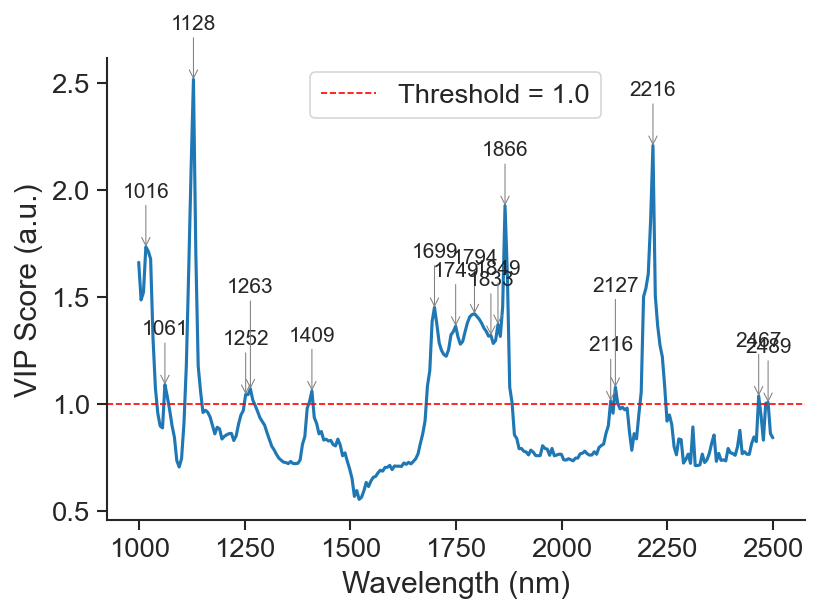

In [23]:
# Annotated VIP
plt.figure(figsize=(6, 4))
sns.lineplot(data=df_vip_swir, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None)
plt.axhline(y=1.0, color="red", linestyle="--", label="Threshold = 1.0", lw=0.8)
y_min, y_max = plt.ylim()
prev_x, offset = None, 0
for x in sorted(biomarkers_swir):
    score = df_vip_swir.loc[df_vip_swir["Wavelength"] == x, "VIP Score"].iloc[0]
    offset = (offset + 1) if (prev_x is not None and abs(x - prev_x) < 15) else 0
    prev_x = x
    plt.annotate(f"{int(round(x))}", xy=(x, score),
        xytext=(x, score + (y_max - y_min) * 0.1 * (offset + 1)),
        ha="center", va="bottom", fontsize=10,
        arrowprops=dict(arrowstyle="->", color="gray", lw=0.5, shrinkA=0, shrinkB=0))
plt.xlabel("Wavelength (nm)")
plt.ylabel("VIP Score (a.u.)")
plt.legend()
# plt.title("SWIR — PLSR VIP Scores (annotated)")
plt.show()


## 7. Cross-Sensor Comparison

Summary of predictive performance (pooled LOGO CV) and side-by-side VIP spectra.

In [24]:
comparison = {
    "Sensor":      ["VNIR",                                   "SWIR"],
    "n_comp":      [result_vnir["n_components"],              result_swir["n_components"]],
    "RMSE (ppm)":  [f"{result_vnir['metrics']['rmse']:.2f}",  f"{result_swir['metrics']['rmse']:.2f}"],
    "R²":          [f"{result_vnir['metrics']['r2']:.4f}",   f"{result_swir['metrics']['r2']:.4f}"],
}
df_comparison = pd.DataFrame(comparison).set_index("Sensor")
print("=== Cross-Sensor PLSR Performance (LOGO CV) ===")
df_comparison


=== Cross-Sensor PLSR Performance (LOGO CV) ===


,n_comp,RMSE (ppm),R²
Sensor,,,
VNIR,17,228.40,0.7325
SWIR,9,206.95,0.7804


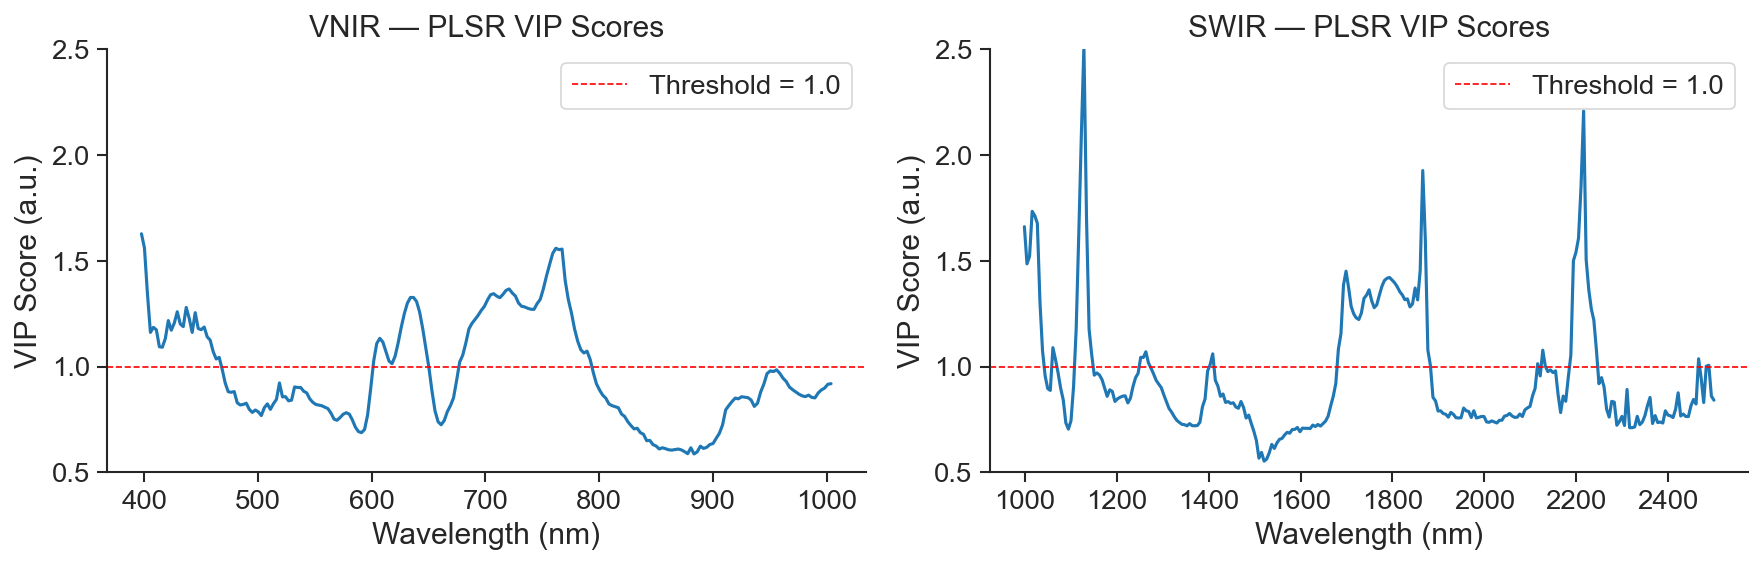

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for ax in [ax1, ax2]:
    ax.set_yticks(np.arange(0.5, 3.0, 0.5))
    ax.set_ylim(0.5, 2.5)
sns.lineplot(data=df_vip_vnir, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None, ax=ax1)
ax1.axhline(y=1.0, color="red", linestyle="--", lw=0.8, label="Threshold = 1.0")
ax1.set_xlabel("Wavelength (nm)")
ax1.set_ylabel("VIP Score (a.u.)")
ax1.set_title("VNIR — PLSR VIP Scores")
ax1.legend()

sns.lineplot(data=df_vip_swir, x="Wavelength", y="VIP Score",
             estimator=None, errorbar=None, ax=ax2)
ax2.axhline(y=1.0, color="red", linestyle="--", lw=0.8, label="Threshold = 1.0")
ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel("VIP Score (a.u.)")
ax2.set_title("SWIR — PLSR VIP Scores")
ax2.legend()

plt.tight_layout()
plt.show()
